In [ ]:
import numpy as np
import mne
import pickle

1. Load events

In [18]:
directory_name = "labelled_data_200hz.nc condition=accuracy n_participants=19 baseline=(None, -0.15) steps=30 cycles=(3, 8) 2026-09-30"

with open(f"output/{directory_name}/tfr/tfr_dict_combined.pkl", 'rb') as file: tfr_dict_combined, _ = pickle.load(file)
with open(f"output/{directory_name}/tfr/tfr_dict_individual.pkl", 'rb') as file: tfr_dict_individual = pickle.load(file)


with open(f"output/{directory_name}/itc/itc_dict_combined.pkl", 'rb') as file: itc_dict_combined, _ = pickle.load(file)
with open(f"output/{directory_name}/itc/itc_dict_individual.pkl", 'rb') as file: itc_dict_individual = pickle.load(file)

2. Create permutation clusters

In [57]:
event_name = '2: decision'
channel = 'all'
individual_dict = itc_dict_individual
combined_dict = itc_dict_combined


data = np.stack([x._data.astype('float16') for x in individual_dict[event_name]])
event = individual_dict[event_name][0]

if channel == 'all': data = np.average(data,axis=1)
else: data = data[:,channel,:,:]

t_obs, clusters, cluster_pv, H0 = mne.stats.permutation_cluster_1samp_test(data, n_permutations=1000, tail=1, n_jobs=-1, out_type='mask')
indices = np.where(cluster_pv <= 0.05)
if indices[0].shape[0] > 0: mask = np.stack([clusters[x] for x in indices[0]])
else: mask = [np.zeros((data.shape[2], data.shape[3]))]

Using a threshold of 1.734064
stat_fun(H1): min=nan max=nan
Running initial clustering …
Found 61 clusters


C:\Users\arian\AppData\Local\Temp\ipykernel_33244\3854545501.py:13: RuntimeWarning: Provided stat_fun does not treat variables independently. Setting buffer_size to None.
  t_obs, clusters, cluster_pv, H0 = mne.stats.permutation_cluster_1samp_test(data, n_permutations=1000, tail=1, n_jobs=-1, out_type='mask')


  0%|          | Permuting : 0/999 [00:00<?,       ?it/s]

3. Plot data

No baseline correction applied


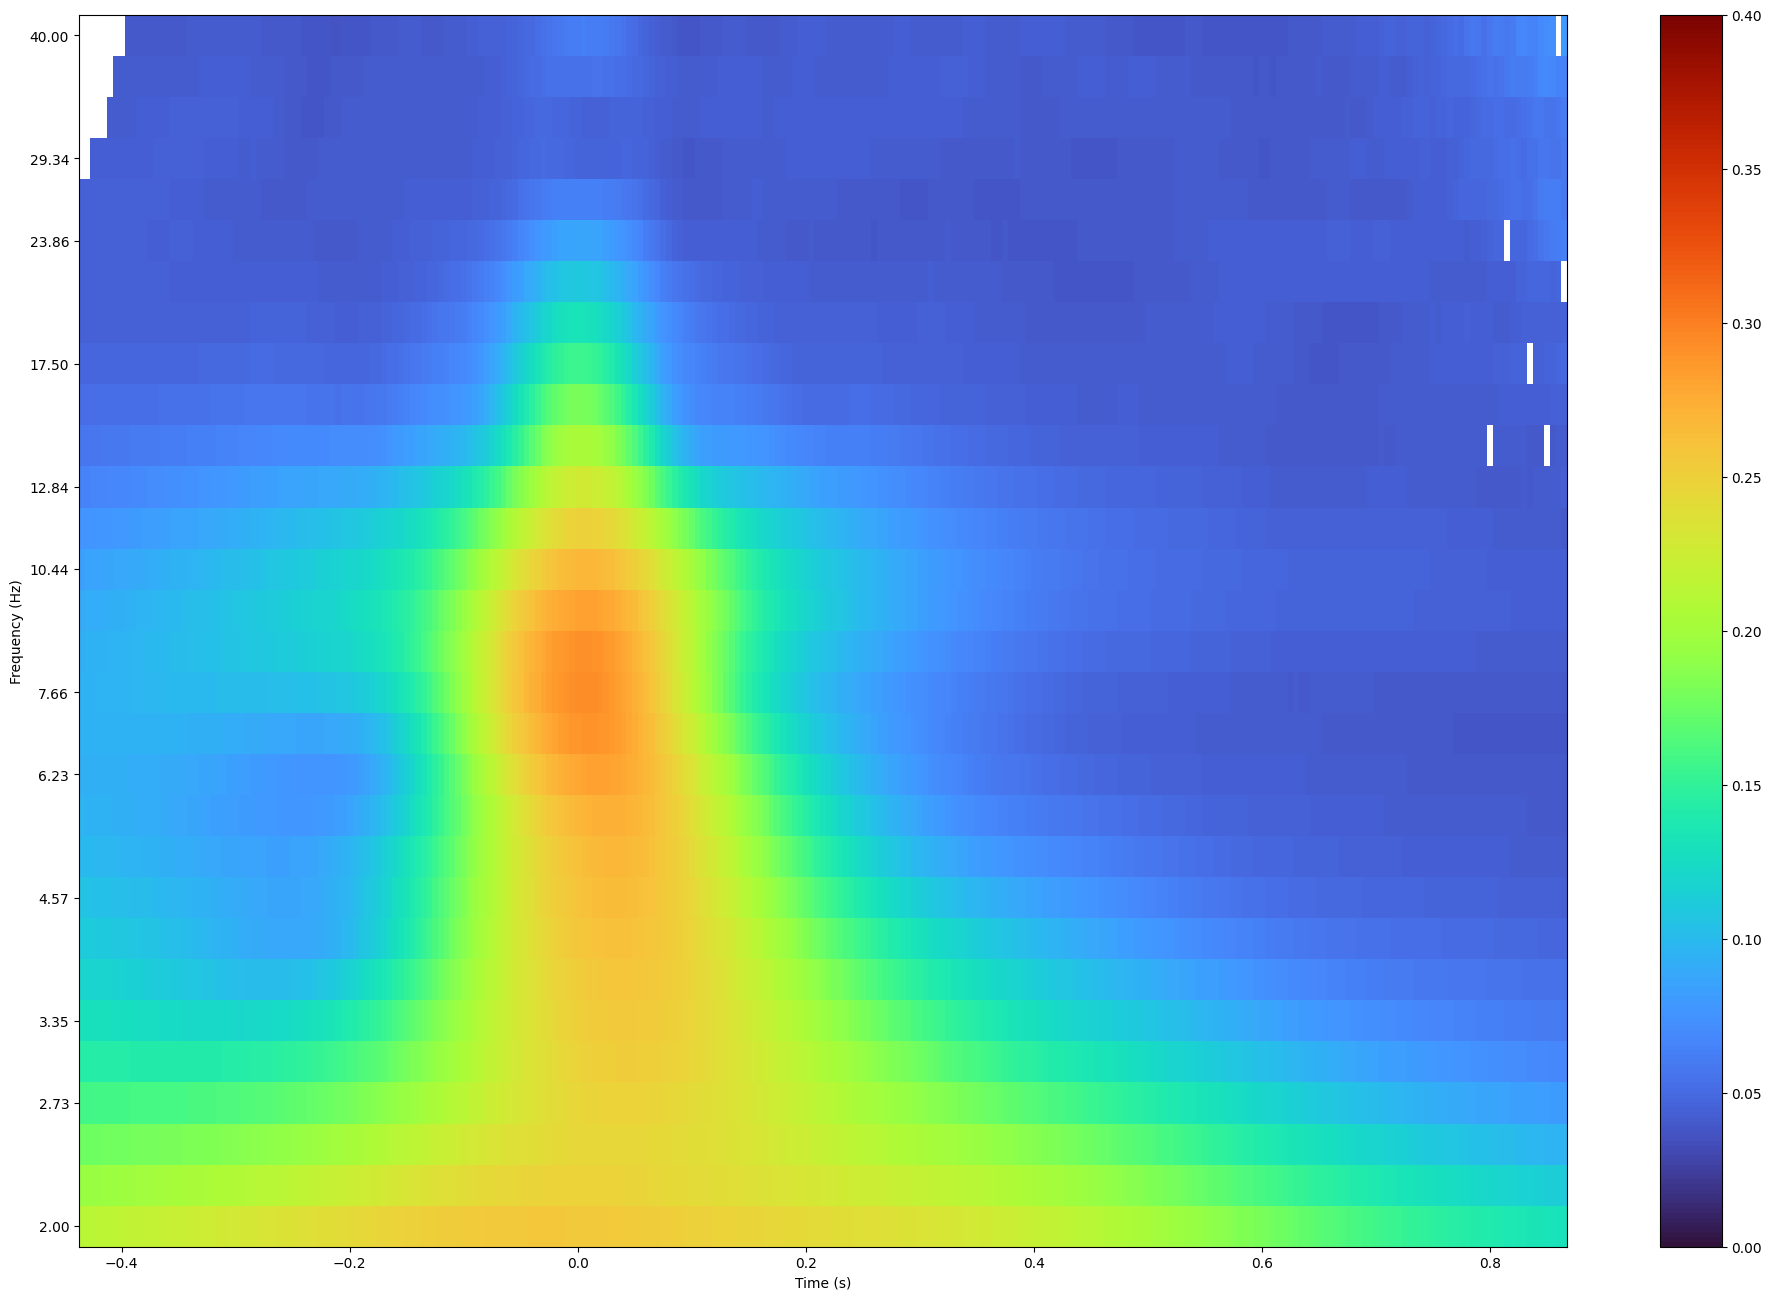

In [58]:
#parameters                                                         #channels to be plotted
vmin, vmax = (0, 0.4)                                                     #power
left, right = AvT.adaptive_xaxis(event, 'samples')               #frequency (Hz)
tmin, tmax = AvT.adaptive_xaxis(event, 'time')

#plot total TFR
_, ax = plt.subplots(figsize=(24,16))
combined_dict[event_name].plot(axes=ax, picks=channel, tmax=tmax, tmin=tmin, vlim=(vmin, vmax), show=False, cmap='turbo', combine='mean', mask=mask[0][:, int(left):int(right)])

plt.show()